In [1]:
%pip install tensorflow

  Using cached tensorflow-2.21.0-cp313-cp313-win_amd64.whl.metadata (4.5 kB)
Using cached tensorflow-2.21.0-cp313-cp313-win_amd64.whl (351.2 MB)
Note: you may need to restart the kernel to use updated packages.


In [1]:
import tensorflow as tf
from keras.models import Sequential
from keras.datasets import mnist
import matplotlib.pyplot as plt
import random
import numpy as np


In [2]:
(x_train, y_train), (x_test, y_test) = mnist.load_data()
x_train=x_train/255
x_test=x_test/255

In [3]:
from keras.src.models import sequential
import keras
model=Sequential()
model.add(keras.layers.Flatten(input_shape=(28,28)))
model.add(keras.layers.Dense(128,activation='relu'))
model.add(keras.layers.Dense(10,activation='softmax'))

C:\Users\aditi\anaconda3\Lib\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [4]:
model.compile(optimizer='sgd',loss='sparse_categorical_crossentropy',metrics=['accuracy'])
H=model.fit(x_train,y_train,validation_data=(x_test,y_test),epochs=5)


Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 3ms/step - accuracy: 0.8391 - loss: 0.6381 - val_accuracy: 0.9031 - val_loss: 0.3619
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9057 - loss: 0.3402 - val_accuracy: 0.9183 - val_loss: 0.2966
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9176 - loss: 0.2918 - val_accuracy: 0.9261 - val_loss: 0.2662
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - accuracy: 0.9264 - loss: 0.2621 - val_accuracy: 0.9315 - val_loss: 0.2406
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9329 - loss: 0.2391 - val_accuracy: 0.9365 - val_loss: 0.2247


In [5]:
test_loss ,test_acc=model.evaluate(x_test,y_test)
print("Loss=%.3f" %test_loss)
print("Accuracy=%.3f" %test_acc)


313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9365 - loss: 0.2247 
Loss=0.225
Accuracy=0.937


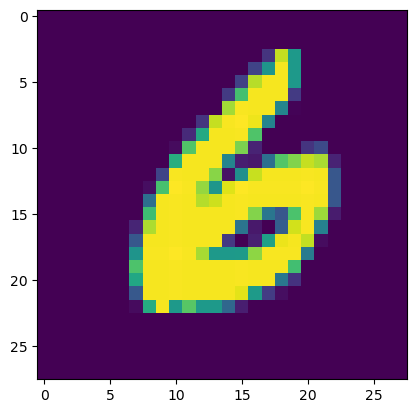

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step  
The handwritten number in image is 6


In [6]:
n=random.randint(0,9999)
plt.imshow(x_test[n])
plt.show()
prediction=model.predict(x_test)
print("The handwritten number in image is %d" %np.argmax(prediction[n]))

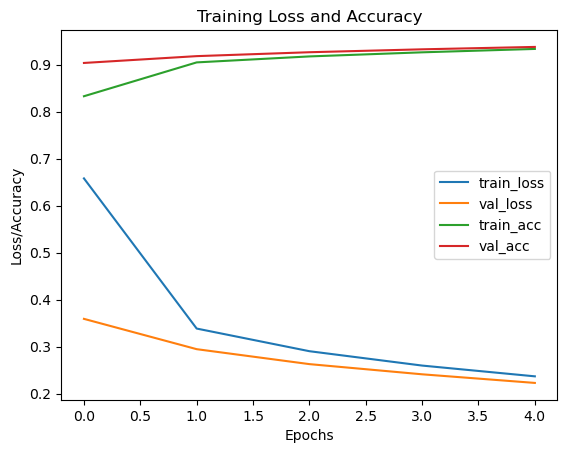

In [8]:
import matplotlib.pyplot as plt

plt.plot(H.history['loss'], label='train_loss')
plt.plot(H.history['val_loss'], label='val_loss')
plt.plot(H.history['accuracy'], label='train_acc')
plt.plot(H.history['val_accuracy'], label='val_acc')

plt.title('Training Loss and Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Loss/Accuracy')
plt.legend()

plt.show()